# Flood-victim external test | Zero-shot pretrained YOLO11l vs YOLO12l

**Goal:** Run **off-the-shelf COCO-pretrained detection weights** (`yolo11l.pt` and/or `yolo12l.pt`) against the images from the attached external test dataset **without fine-tuning**, keeping only COCO class `0 = person`.

**Outputs:** annotated `.png`, Adobe Illustrator-friendly `.eps` with **vector bounding boxes and text** over the *embedded raster photo*, confidence-bearing YOLO `.txt` predictions, image-level and box-level `.csv`, optional ground-truth evaluation, and **one ZIP for all PNGs + another ZIP for all EPS files**. Every model has its own output subfolder.

**Kaggle preparation:** Add your original `floodvictim-external` Kaggle dataset, enable **GPU** (recommended) and **Internet** (required for first-time `pip`/pretrained weight downloads). No checkpoint from the C2A-finetuned dataset is used. If Internet is disabled, attach the official `.pt` weights as an input dataset and set their paths in the configuration cell.

**Important:** The `.eps` contains an embedded raster *photograph*; the boxes and confidence labels are vector elements. Changing line widths, colors, and annotations in Illustrator is possible after importing/ungrouping, but EPS cannot turn a photo into a true vector image. These predictions are *not evidence of flood victims* by themselves; they are generic COCO `person` detections.

## 1. Install / update Ultralytics

In [1]:
# Internet ON for first-time installation / downloading pretrained weights.
import sys
import subprocess
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "ultralytics"])
print("Ultralytics installation complete.")

Ultralytics installation complete.


## 2. Configuration — edit only this cell if needed

In [2]:
from pathlib import Path
import json
import zipfile
import warnings
import gc

import cv2
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Image as IPyImage, FileLink
from ultralytics import YOLO
import ultralytics

# Default path copied from your uploaded notebook.
IMAGE_DIR = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images")
LABEL_DIR = IMAGE_DIR.parent / "labels"  # optional; only used for evaluation

# Run both for comparison, or remove one entry to run only that model.
MODEL_WEIGHTS = {
    "YOLO11l": "yolo11l.pt",  # official COCO-pretrained weight
    #"YOLO12l": "yolo12l.pt",  # official COCO-pretrained weight
}
# Offline alternative example (first attach the actual weights to Kaggle):
# MODEL_WEIGHTS["YOLO12l"] = "/kaggle/input/my-weights/yolo12l.pt"

OUT_DIR = Path("/kaggle/working/pretrained_person_comparison")
IMGSZ = 640
CONF = 0.25                 # threshold for exported predictions / images
IOU = 0.70                  # non-max suppression threshold
BATCH = 4                   # decrease to 1 if out-of-memory
DEVICE = 0 if torch.cuda.is_available() else "cpu"
PERSON_CLASS = 0            # COCO: class 0 is person

EXPORT_EPS = True
EXPORT_PNG = True
EXPORT_SVG = False          # optional: SVG is often even easier to edit in Illustrator
PNG_DPI = 120               # saves PNG at the input image's pixel dimensions
EPS_RASTER_DPI = 120        # DPI of embedded photo only; boxes remain vector
BOX_COLOR = "#E85D3F"      # annotation outline/label color
BOX_LINEWIDTH_PT = 2.0
LABEL_FONTSIZE_PT = 9.0

# Set True to compute P/R/mAP using YOLO-format ground truth in sibling labels/.
# This runs *validation*, not training or fine-tuning.
RUN_VALIDATION = True
VAL_BATCH = 4
SHOW_PREVIEW = 2           # preview first N PNGs per model, 0 = none

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Models:", MODEL_WEIGHTS)
print("Export folder:", OUT_DIR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.215
PyTorch: 2.11.0+cu130
Device: 0
Models: {'YOLO11l': 'yolo11l.pt'}
Export folder: /kaggle/working/pretrained_person_comparison


## 3. Confirm the dataset and ground-truth layout

The notebook uses the original uploaded notebook's image-folder path, with a fallback search for the same `floodVictim_external/images` directory if Kaggle mounts it under another prefix. Existing labels are **never used for inference**. They are only used for optional evaluation; expected label format is `class_id x_center y_center width height` (normalized), with class ID `0` for human/person.

In [3]:
if not IMAGE_DIR.is_dir():
    search_root = Path("/kaggle/input")
    alternatives = sorted(
        p for p in search_root.rglob("images")
        if p.is_dir() and p.parent.name.lower() == "floodvictim_external"
    ) if search_root.exists() else []
    if len(alternatives) == 1:
        IMAGE_DIR = alternatives[0]
        LABEL_DIR = IMAGE_DIR.parent / "labels"
        print("Autodetected image directory:", IMAGE_DIR)
    else:
        raise FileNotFoundError(
            f"Image directory missing: {IMAGE_DIR}\n"
            f"Found {len(alternatives)} possible alternatives: {alternatives[:10]}\n"
            "Add the floodvictim-external dataset to this Kaggle notebook, or edit IMAGE_DIR."
        )

SUPPORTED_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
images = sorted(p for p in IMAGE_DIR.iterdir() if p.is_file() and p.suffix.lower() in SUPPORTED_EXT)
if not images:
    raise RuntimeError(f"No supported images found in {IMAGE_DIR}")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# All images are flat (same as original .iterdir() notebook); unique output names.
output_names = {str(p.resolve()): f"{p.stem}__{p.suffix.lower().lstrip('.')}" for p in images}
if len(set(output_names.values())) != len(images):
    raise ValueError("Output name collision detected. Rename conflicting input files.")

label_files = [LABEL_DIR / f"{p.stem}.txt" for p in images]
existing_labels = [p for p in label_files if p.is_file()]
nonempty_labels = [p for p in existing_labels if p.stat().st_size > 0]
print("Images:", len(images), "| Image path:", IMAGE_DIR)
print("GT label files:", len(existing_labels), "| Nonempty:", len(nonempty_labels))
print("Example input images:", [p.name for p in images[:5]])
if RUN_VALIDATION and not nonempty_labels:
    print("No positive YOLO GT labels found; evaluation will be skipped. Inference will run normally.")

Images: 27 | Image path: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
GT label files: 27 | Nonempty: 27
Example input images: ['flood01.jpg', 'flood02.jpg', 'flood03.jpg', 'flood04.jpg', 'flood05.webp']


## 4. Export utilities

PNG and EPS are generated from the **same Matplotlib figure**, so image overlays have matching geometry. The photograph is embedded as raster; rectangles and text are independently drawn as vector graphics in EPS. Predicted YOLO-label `.txt` lines store `class xc yc w h confidence`.

In [4]:
# Type 42 keeps TrueType fonts embedded in EPS; Illustrator may still require ungrouping.
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.max_open_warning"] = 0

DETECTION_COLUMNS = [
    "model", "image", "class_id", "class_name", "confidence",
    "x1", "y1", "x2", "y2", "image_width", "image_height"
]
SUMMARY_COLUMNS = ["model", "image", "person_detections", "max_confidence", "image_width", "image_height"]


def read_person_boxes(result):
    if result.boxes is None or len(result.boxes) == 0:
        return []
    xyxy = result.boxes.xyxy.detach().cpu().numpy()
    confs = result.boxes.conf.detach().cpu().numpy()
    classes = result.boxes.cls.detach().cpu().numpy().astype(int)
    return [(tuple(map(float, coords)), float(conf))
            for coords, conf, cls in zip(xyxy, confs, classes) if cls == PERSON_CLASS]


def save_annotated_figures(original_bgr, boxes, png_path, eps_path, svg_path=None):
    """Identical raster preview + Illustrator-editable vector bounding boxes in EPS/SVG."""
    h, w = original_bgr.shape[:2]
    rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    fig = plt.figure(figsize=(w / PNG_DPI, h / PNG_DPI), dpi=PNG_DPI, facecolor="white")
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(rgb, extent=(0, w, h, 0), origin="upper", interpolation="nearest")
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)
    ax.set_aspect("auto")
    ax.axis("off")
    for (x1, y1, x2, y2), conf in boxes:
        ax.add_patch(Rectangle((x1, y1), max(0, x2-x1), max(0, y2-y1),
                               linewidth=BOX_LINEWIDTH_PT, edgecolor=BOX_COLOR,
                               facecolor="none", zorder=5))
        label = f"person {conf:.2f}"
        label_y = y1 - 5 if y1 > 22 else y1 + 5
        ax.text(x1 + 2, label_y, label,
                fontsize=LABEL_FONTSIZE_PT, fontweight="normal",
                color="white", va="bottom" if y1 > 22 else "top", ha="left",
                bbox={"facecolor": BOX_COLOR, "edgecolor": "none", "pad": 1.5},
                zorder=6, clip_on=True)
    try:
        if png_path is not None:
            fig.savefig(png_path, format="png", dpi=PNG_DPI, pad_inches=0, facecolor="white")
        if eps_path is not None:
            # EPS backend preserves vector patches/text while embedding the photo as raster.
            fig.savefig(eps_path, format="eps", dpi=EPS_RASTER_DPI, pad_inches=0, facecolor="white")
        if svg_path is not None:
            fig.savefig(svg_path, format="svg", dpi=EPS_RASTER_DPI, pad_inches=0, facecolor="white")
    finally:
        plt.close(fig)


def save_yolo_predictions(boxes, w, h, label_path):
    with open(label_path, "w", encoding="utf-8") as fh:
        for (x1, y1, x2, y2), conf in boxes:
            xc = ((x1+x2)/2)/w
            yc = ((y1+y2)/2)/h
            bw = (x2-x1)/w
            bh = (y2-y1)/h
            fh.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f} {conf:.6f}\n")


def make_zip(zip_path, files_and_arcnames):
    count = 0
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True) as zf:
        for source, arcname in files_and_arcnames:
            if source.is_file():
                zf.write(source, arcname=str(arcname))
                count += 1
    print(f"{zip_path.name}: {count} files, {zip_path.stat().st_size/1024**2:.1f} MB")
    return count

## 5. Run ZERO-SHOT inference and save every image

Each model is loaded from its official COCO-pretrained `.pt` file. `classes=[0]` ensures only person detections survive filtering. No `train()` call, optimizer, or fine-tuned checkpoint is used.

In [5]:
all_detection_rows = []
all_image_rows = []
loaded_models = {}

for model_name, weights in MODEL_WEIGHTS.items():
    print(f"\n{'='*70}\nModel: {model_name} | Weights: {weights}\n{'='*70}")
    model_dir = OUT_DIR / model_name
    png_dir = model_dir / "png"
    eps_dir = model_dir / "eps"
    svg_dir = model_dir / "svg"
    txt_dir = model_dir / "labels_txt"
    for d in (png_dir, eps_dir, txt_dir):
        d.mkdir(parents=True, exist_ok=True)
    if EXPORT_SVG:
        svg_dir.mkdir(parents=True, exist_ok=True)

    try:
        model = YOLO(weights)
    except Exception as exc:
        raise RuntimeError(
            f"Failed to load {weights}. Enable Kaggle Internet to download official pretrained "
            f"weights, or attach the checkpoint as a dataset and set its path in MODEL_WEIGHTS."
        ) from exc
    if str(model.names.get(PERSON_CLASS, "")).lower() != "person":
        raise ValueError(f"Unexpected class mapping: index 0 is {model.names.get(PERSON_CLASS)!r}, not 'person'.")
    loaded_models[model_name] = model
    processed = 0
    detections = 0
    # Directory source + stream=True avoids retaining all input images/predictions in RAM.
    results = model.predict(
        source=str(IMAGE_DIR),
        imgsz=IMGSZ,
        conf=CONF,
        iou=IOU,
        classes=[PERSON_CLASS],
        device=DEVICE,
        batch=BATCH,
        stream=True,
        save=False,
        verbose=False,
    )
    for result in results:
        source_path = Path(result.path).resolve()
        if str(source_path) not in output_names:
            # The user supplies an images-only folder; reject unplanned/mismatched entries.
            raise RuntimeError(f"Unrecognized inference input: {result.path}")
        basename = output_names[str(source_path)]
        h, w = result.orig_img.shape[:2]
        boxes = read_person_boxes(result)
        png_file = png_dir / f"{basename}.png" if EXPORT_PNG else None
        eps_file = eps_dir / f"{basename}.eps" if EXPORT_EPS else None
        svg_file = svg_dir / f"{basename}.svg" if EXPORT_SVG else None
        save_annotated_figures(result.orig_img, boxes, png_file, eps_file, svg_file)
        save_yolo_predictions(boxes, w, h, txt_dir / f"{basename}.txt")
        all_image_rows.append({
            "model": model_name, "image": source_path.name, "person_detections": len(boxes),
            "max_confidence": max((conf for _, conf in boxes), default=0.0),
            "image_width": w, "image_height": h,
        })
        for (x1, y1, x2, y2), conf in boxes:
            all_detection_rows.append({
                "model": model_name, "image": source_path.name,
                "class_id": PERSON_CLASS, "class_name": "person", "confidence": conf,
                "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                "image_width": w, "image_height": h,
            })
        processed += 1
        detections += len(boxes)
        if processed % 10 == 0 or processed == len(images):
            print(f"  {processed}/{len(images)} images | {detections} detections")
    if processed != len(images):
        raise RuntimeError(f"Expected {len(images)} images, but {model_name} processed {processed}.")
    print(f"Finished {model_name}: {processed} images, {detections} person boxes")

image_df = pd.DataFrame(all_image_rows, columns=SUMMARY_COLUMNS)
detection_df = pd.DataFrame(all_detection_rows, columns=DETECTION_COLUMNS)
image_df.to_csv(OUT_DIR / "image_summary.csv", index=False)
detection_df.to_csv(OUT_DIR / "detections.csv", index=False)
display(image_df.groupby("model", as_index=False).agg(
    images=("image", "size"), total_person_boxes=("person_detections", "sum"),
    images_with_people=("person_detections", lambda s: int((s > 0).sum()))
))


Model: YOLO11l | Weights: yolo11l.pt
  10/27 images | 76 detections
  20/27 images | 141 detections
  27/27 images | 216 detections
Finished YOLO11l: 27 images, 216 person boxes


,model,images,total_person_boxes,images_with_people
0,YOLO11l,27,216,26


## 6. Optional quantitative evaluation (only if labels are available)

**Evaluation requires actual human/person ground truth** stored as normalized YOLO TXT (`labels/<image_stem>.txt`, class 0). It uses the same external images as the existing notebook. `model.val()` **does not fine-tune the model**. Its low confidence threshold (`0.001`) supports the AP curve, so the validation counts may differ from the exported PNGs (which use `CONF = 0.25`).

The validation set is only one class; the COCO class is filtered to `classes=[0]` (person). Do not present mAP as verified if the annotations are incomplete or the class mapping differs.

In [6]:
metrics_rows = []
can_evaluate = RUN_VALIDATION and LABEL_DIR.is_dir() and len(nonempty_labels) > 0

if can_evaluate:
    # Fail early for non-person classes; all GT objects should be class_id 0.
    class_ids = set()
    for f in nonempty_labels:
        for line in f.read_text(encoding="utf-8").splitlines():
            fields = line.strip().split()
            if fields:
                if len(fields) < 5:
                    raise ValueError(f"Invalid YOLO GT label line in {f}: {line}")
                class_ids.add(int(float(fields[0])))
    if class_ids != {0}:
        raise ValueError(f"Expected only person/human GT class 0, got {sorted(class_ids)}. Review the label mapping.")
    if len(existing_labels) < len(images):
        print("WARNING: Some images have no corresponding label files; inspect whether those are genuinely negatives.")

    val_yaml_path = OUT_DIR / "pretrained_person_val.yaml"
    val_config = {
        "path": str(IMAGE_DIR.parent),
        "train": str(IMAGE_DIR),
        "val": str(IMAGE_DIR),
        "test": str(IMAGE_DIR),
        "nc": 1,
        "names": {0: "person"},
    }
    with val_yaml_path.open("w") as fh:
        yaml.safe_dump(val_config, fh, sort_keys=False)

    evaluation_errors = {}
    for model_name, model in loaded_models.items():
        print(f"\nEvaluating {model_name} (person only; no training) ...")
        try:
            # Ultralytics validation computes standard detection metrics (mAP/AP).
            metrics = model.val(
                data=str(val_yaml_path),
                split="test",
                imgsz=IMGSZ,
                batch=VAL_BATCH,
                conf=0.001,
                iou=IOU,
                classes=[PERSON_CLASS],
                device=DEVICE,
                plots=True,
                project=str(OUT_DIR / model_name),
                name="validation",
                exist_ok=True,
                verbose=False,
            )
            p = float(metrics.box.mp)
            r = float(metrics.box.mr)
            metrics_rows.append({
                "model": model_name,
                "precision": p,
                "recall": r,
                "f1_from_mean_precision_recall": (2*p*r/(p+r)) if (p+r)>0 else 0.0,
                "mAP50": float(metrics.box.map50),
                "mAP50_95": float(metrics.box.map),
                "evaluation_confidence": 0.001,
            })
        except Exception as exc:
            # Preserve the user's primary result: inference images and downloadable ZIPs.
            evaluation_errors[model_name] = str(exc)
            print(f"WARNING: Validation failed for {model_name}: {type(exc).__name__}: {exc}")
            print("Inference images remain intact; check dataset/labels and try VAL_BATCH=1 if needed.")
    if evaluation_errors:
        (OUT_DIR / "evaluation_errors.json").write_text(json.dumps(evaluation_errors, indent=2), encoding="utf-8")

else:
    print("Evaluation skipped (RUN_VALIDATION=False or GT person labels unavailable).")

metrics_df = pd.DataFrame(metrics_rows)
if not metrics_df.empty:
    metrics_df.to_csv(OUT_DIR / "metrics.csv", index=False)
    display(metrics_df)
else:
    print("No verified precision, recall, or mAP computed.")


Evaluating YOLO11l (person only; no training) ...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11l summary (fused): 190 layers, 25,340,992 parameters, 0 gradients, 87.2 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 237.9±162.9 MB/s, size: 132.6 KB)
val: Scanning /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 715.2it/s 0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.6it/s 2.7s0.2ss
                   all         27        288      0.817      0.744      0.852      0.596
Speed: 0.8ms preprocess, 36.2ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /kaggle/working/pretrained_person_comparison/

,model,precision,recall,f1_from_mean_precision_recall,mAP50,mAP50_95,evaluation_confidence
0,YOLO11l,0.816894,0.743554,0.7785,0.851968,0.596137,0.001


## 7. Create downloadable ZIP archives

The PNG ZIP includes **both models' annotated images**, organized as `YOLO11l/png/...` and `YOLO12l/png/...`; the EPS ZIP has the same structure. The tables/label TXT files go in a third, smaller ZIP. Large archives are ZIP64-enabled.

In [7]:
run_info = {
    "dataset_image_dir": str(IMAGE_DIR),
    "labels_dir": str(LABEL_DIR),
    "image_count": len(images),
    "models": MODEL_WEIGHTS,
    "pretraining": "COCO (unmodified official pretrained checkpoints)",
    "fine_tuning": False,
    "person_class": 0,
    "image_size": IMGSZ,
    "prediction_confidence": CONF,
    "nms_iou": IOU,
    "validation_run": can_evaluate,
    "ultralytics_version": ultralytics.__version__,
    "note": "PNG and EPS annotate person detections. EPS embeds raster photograph but draws boxes/text as vector."
}
(OUT_DIR / "run_settings.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")

png_files = sorted(OUT_DIR.glob("*/png/*.png"))
eps_files = sorted(OUT_DIR.glob("*/eps/*.eps"))
svg_files = sorted(OUT_DIR.glob("*/svg/*.svg"))
tables_files = (
    sorted(OUT_DIR.glob("*.csv")) +
    sorted(OUT_DIR.glob("*.json")) +
    sorted(OUT_DIR.glob("*.yaml")) +
    sorted(OUT_DIR.glob("*/labels_txt/*.txt"))
)

png_zip = OUT_DIR / "ALL_DETECTIONS_PNG.zip"
eps_zip = OUT_DIR / "ALL_DETECTIONS_EPS.zip"
results_zip = OUT_DIR / "RESULTS_CSV_AND_LABELS.zip"
make_zip(png_zip, [(f, f.relative_to(OUT_DIR)) for f in png_files])
make_zip(eps_zip, [(f, f.relative_to(OUT_DIR)) for f in eps_files])
make_zip(results_zip, [(f, f.relative_to(OUT_DIR)) for f in tables_files])
if EXPORT_SVG:
    make_zip(OUT_DIR / "ALL_DETECTIONS_SVG.zip", [(f, f.relative_to(OUT_DIR)) for f in svg_files])

print("\nDownload ZIP files from the Kaggle /kaggle/working output panel:")
for f in [png_zip, eps_zip, results_zip]:
    display(FileLink(str(f)))
if EXPORT_SVG:
    display(FileLink(str(OUT_DIR / "ALL_DETECTIONS_SVG.zip")))
print("All exports saved under:", OUT_DIR)

ALL_DETECTIONS_PNG.zip: 27 files, 38.0 MB
ALL_DETECTIONS_EPS.zip: 27 files, 54.0 MB
RESULTS_CSV_AND_LABELS.zip: 32 files, 0.0 MB

Download ZIP files from the Kaggle /kaggle/working output panel:


/kaggle/working/pretrained_person_comparison/ALL_DETECTIONS_PNG.zip

/kaggle/working/pretrained_person_comparison/ALL_DETECTIONS_EPS.zip

/kaggle/working/pretrained_person_comparison/RESULTS_CSV_AND_LABELS.zip

All exports saved under: /kaggle/working/pretrained_person_comparison


## 8. Preview and interpret the outcome

YOLO11l — flood01__jpg.png


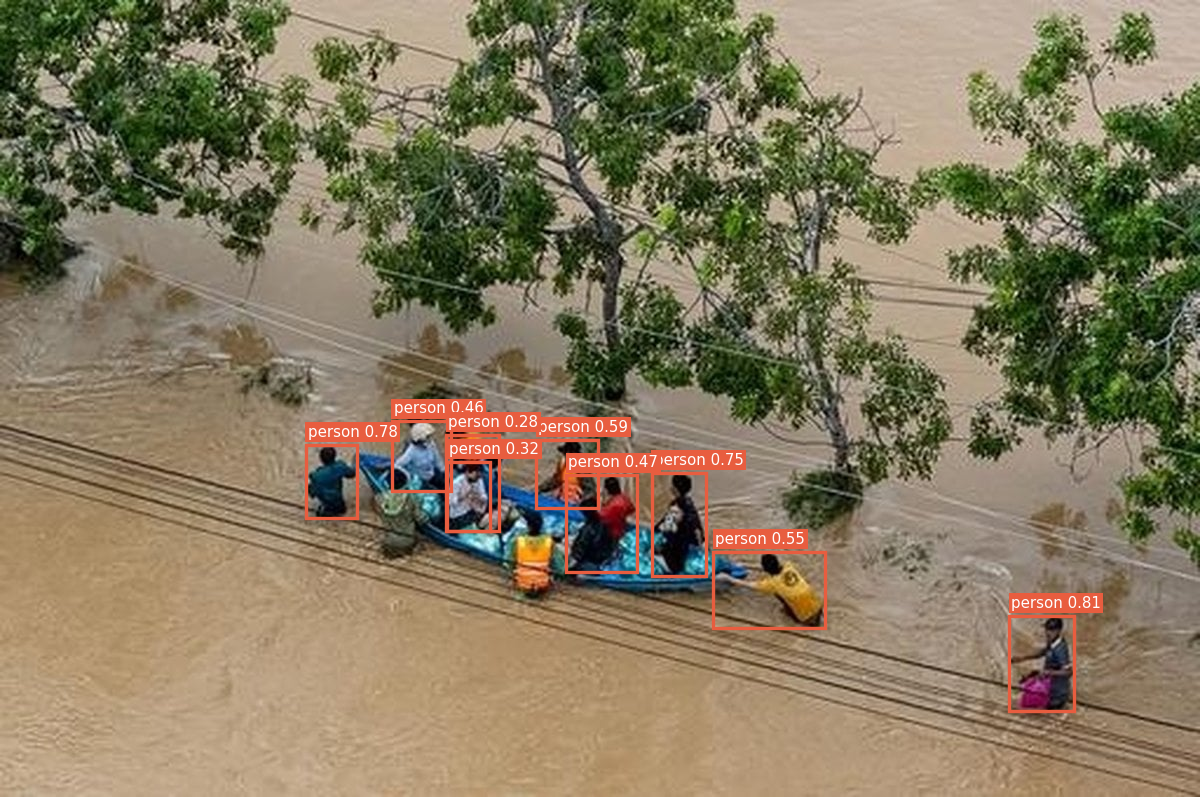

YOLO11l — flood02__jpg.png


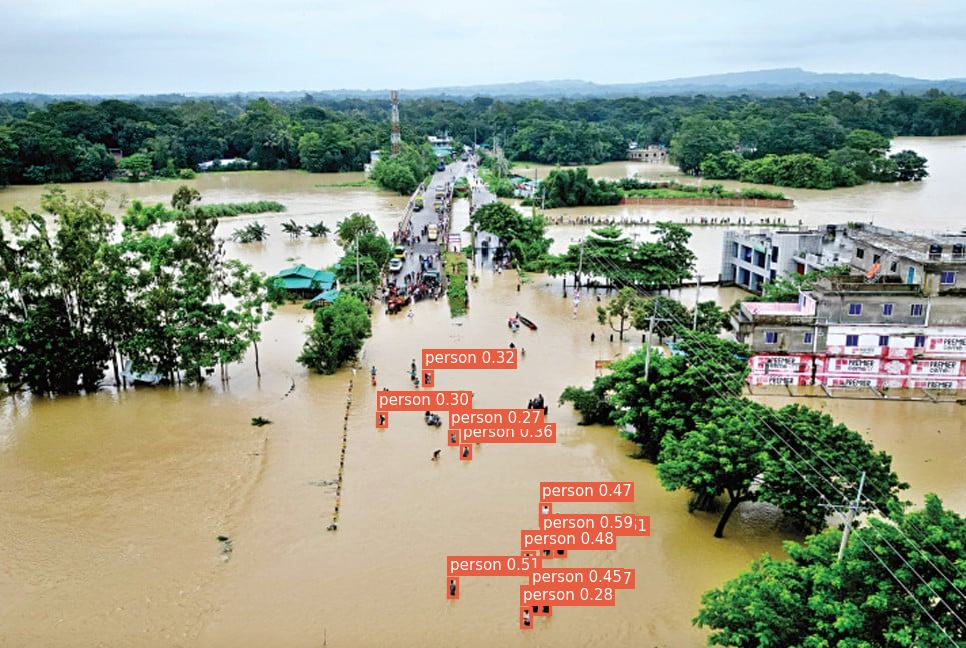


Model comparison (detection counts; counts alone are not accuracy):


,model,images,images_with_people,total_person_boxes
0,YOLO11l,27,26,216


For scientific reporting, use ground-truth P/R/mAP when available; visually inspect domain-shift errors.


In [8]:
if SHOW_PREVIEW:
    for name in MODEL_WEIGHTS:
        files = sorted((OUT_DIR / name / "png").glob("*.png"))[:SHOW_PREVIEW]
        for f in files:
            print(name, "—", f.name)
            display(IPyImage(filename=str(f), width=700))

print("\nModel comparison (detection counts; counts alone are not accuracy):")
display(image_df.groupby("model", as_index=False).agg(
    images=("image", "size"),
    images_with_people=("person_detections", lambda s: int((s > 0).sum())),
    total_person_boxes=("person_detections", "sum"),
))
print("For scientific reporting, use ground-truth P/R/mAP when available; visually inspect domain-shift errors.")

---
### Notes on scientific interpretation

- **Off-the-shelf baseline:** This run uses pretrained detectors as-is. It tests *cross-domain inference* on flood/UAV images, not an independently trained flood-specific model.
- **Person ≠ victim:** A detection is not evidence of distress, injury, or an actual flood victim. Occlusion, small apparent size, aerial viewing angle, water reflections, and the mismatch between COCO and disaster UAV imagery can cause missed detections/false positives.
- **Confidence vs AP:** Annotated PNG/EPS images show predictions filtered at `CONF`, while validation mAP integrates a much lower confidence range. Different counts are expected.
- **Illustrator:** Opening an EPS lets you adjust vector rectangles and annotation text where supported; the underlying satellite/UAV photo remains an embedded raster. Set `EXPORT_SVG = True` to produce Illustrator-friendly SVG copies as well.
- **Reproducibility:** Record Ultralytics version, weights, image resolution, inference confidence, IoU, and dataset split from `run_settings.json` when writing the paper.

In [9]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

# Folder containing all generated outputs
output_dir = Path("/kaggle/working/pretrained_person_comparison")

# Final downloadable ZIP (outside the source folder)
zip_path = Path("/kaggle/working/ALL_YOLO_OUTPUTS.zip")

if not output_dir.is_dir():
    raise FileNotFoundError(f"Output folder not found: {output_dir}")

# Recursively collect every output file
files = sorted(
    p for p in output_dir.rglob("*")
    if p.is_file()
)

if not files:
    raise RuntimeError("No output files found to ZIP.")

# Create ZIP while preserving folder structure
with ZipFile(
    zip_path,
    mode="w",
    compression=ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True
) as zipf:
    for file in files:
        zipf.write(
            file,
            arcname=file.relative_to(output_dir.parent)
        )

size_mb = zip_path.stat().st_size / (1024 ** 2)

print("ZIP successfully created!")
print(f"Total files: {len(files)}")
print(f"ZIP size: {size_mb:.2f} MB")
print(f"Saved to: {zip_path}")

# Download link
display(FileLink(str(zip_path)))

ZIP successfully created!
Total files: 101
ZIP size: 186.14 MB
Saved to: /kaggle/working/ALL_YOLO_OUTPUTS.zip


/kaggle/working/ALL_YOLO_OUTPUTS.zip